# Film analysis: saved data to reproducible results

Run top to bottom from this folder with data_compact.zip beside the notebook. All inputs are cached; plots are exported to figures/. The frozen sample has 100 films, 20 per decade, with one selected measurement page per film. Edition/playback speed remain unverified. Request logs, the passport and current input hashes are retained; Film_Collection verifies the raw sample against the original log.

| Module | Cells | Evidence location |
| --- | --- | --- |
| M1 | Section M1 | Input and dataset profile |
| M2 | Section M2 | M2.5 missingness; M2.7 repeat-page impact; raw audit in Collection |
| M3 | Section M3 | M3.1-M3.9 inputs, preprocessing, similarity and text |
| M4 | Section M4 | M4.1-M4.6 original transactions and saved results |
| M5 | Section M5 | M5.1-M5.3 primitives, aggregate checks and costs |
| M6 | Section M6 | Q1/Q2/Q3, figure index, advanced network |

## M1 Understand the dataset
### M1.1-M1.5 Scope, lifecycle and profile
This descriptive study follows acquisition -> matching/screening -> frozen films -> analysis -> results. The profile below states its units and denominators; site update frequency is unknown. Structured rows and text documents overlap rather than add to the film count.

Pipeline: Titanic HTML example -> TMDB vote-ranked candidates -> Cinemetrics pages -> identity and duration checks -> one page per film -> Q1-Q3. The five decade quotas are purposive; the sample is not a random film population.

The notebook displays only final charts. Blue represents ASL/base counts, coral represents MSL/contrasts, and cyan is used for individual films. Genre colours are fixed across panels, composition and network nodes.
The question is empirical: how did shot length vary in these films? Matching and checking pages is the engineering work. Summarising rhythm and mining genre co-occurrence are descriptive tasks. There is no prediction model. The 505 pages show variation between measurements of 160 films. The 100 selected films supply 100 synopses and 100 genre transactions; rare genres and unmeasured films limit wider claims.

### M1.3 Variety and velocity
 TMDB JSON replies and Cinemetrics HTML have nested structure; request logs use one JSON object per attempt. Parsing produces typed columns such as shot count and ASL; each synopsis remains free text in a table cell. The two channels have different success rates (Collection, “Verify logs and the passport”). The window below includes waits and pauses. Source update frequency is unknown. A future incremental run could revisit known IDs, date each response and compare content hashes before accepting a new snapshot.

Each merged column counts once. The denominator is the 48 parsed fields marked M in the M2.1 dictionary. JSON and HTML describe the source files.

| Parsed field structure | Fields | Share of fields |
|---|---:|---:|
| Structured scalar | 37 | 77.08% |
| Semi-structured list | 8 | 16.67% |
| Unstructured text | 3 | 6.25% |
| **Total** | **48** | **100%** |

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import math
import re
import numpy as np
import pandas as pd
from IPython.display import display

# Analysis needs saved tables and methods, not raw measurement HTML.
from tempfile import TemporaryDirectory
from zipfile import ZipFile
project_dir = Path.cwd()
temp = TemporaryDirectory(prefix="ads206_")
with ZipFile(project_dir / "data_compact.zip") as data:
    for name in data.namelist():
        if name.startswith(("02_audit/", "03_methods/")) or name == "data_passport.json":
            data.extract(name, temp.name)
root = Path(temp.name)
version = json.loads((root / "02_audit/frozen_films_version.json").read_text(encoding="utf-8"))
for field, hash_field in [("table", "table_sha256"), ("source", "source_sha256")]:
    path = root / version[field]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == version[hash_field], f"Frozen input changed: {path}"
film_table = pd.read_csv(root / version["table"], encoding="utf-8-sig")
source = json.loads((root / version["source"]).read_text(encoding="utf-8"))
measurements = pd.DataFrame(source["records"])
# One selected page per film.
selected_rows = measurements.loc[measurements["selected_for_main_analysis"].eq(True)].copy()
pairs = sorted(map(tuple, film_table[["tmdb_id", "page_id"]].values.tolist()))
assert source["final_sample_locked"]
assert hashlib.sha256(json.dumps(pairs, separators=(",", ":")).encode()).hexdigest() == version["frozen_pairs_sha256"]
assert pairs == sorted(map(tuple, selected_rows[["tmdb_id", "page_id"]].values.tolist()))
assert len(film_table) == film_table["tmdb_id"].nunique() == 100
extra = ["msl_seconds", "shot_count", "measured_seconds", "runtime_minutes", "release_date", "year_html"]
main_films = film_table.merge(selected_rows[["tmdb_id", "page_id"] + extra], on=["tmdb_id", "page_id"], validate="one_to_one")
pool_bytes = (root / "02_audit/tmdb_candidates.json").read_bytes()
pool_sha256 = hashlib.sha256(pool_bytes).hexdigest()
pool = json.loads(pool_bytes)
assert pool["run_id"] == version["candidate_run"]
metadata = pd.DataFrame(pool["records"])[["tmdb_id", "genres", "overview_details"]]
main_films = main_films.merge(metadata, on="tmdb_id", how="left", validate="one_to_one")
assert len(main_films) == 100 and main_films["genres"].map(lambda x: isinstance(x, list) and bool(x)).all()
assert main_films["overview_details"].map(lambda x: isinstance(x, str) and len(x.strip()) >= 50).all()
assert np.isfinite(main_films[["asl_seconds", "msl_seconds", "shot_count", "measured_seconds", "runtime_minutes"]]).all().all()
assert main_films[["asl_seconds", "msl_seconds", "shot_count", "measured_seconds", "runtime_minutes"]].gt(0).all().all()
decade_order = [f"{d}s" for d in range(1970, 2020, 10)]
film_counts = main_films.groupby("decade").size().reindex(decade_order)
assert film_counts.eq(20).all()
passport = json.loads((root / "data_passport.json").read_text(encoding="utf-8"))
assert passport["measurement_records"] == len(measurements)
audit_source_sha256 = version["source_sha256"]
print(f"{len(main_films)} frozen films, {film_counts.iloc[0]} per decade.")
figure_folder = project_dir / "figures"
figure_folder.mkdir(exist_ok=True)

import matplotlib.pyplot as plt
palette = {"blue": "#466F87", "cyan": "#78B6C8", "sand": "#F2D98E", "coral": "#E48578", "olive": "#98AF1E"}
genre_colors = {"Adventure": palette["blue"], "Drama": palette["olive"], "Thriller": palette["coral"], "Other labels": palette["sand"]}
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "legend.fontsize": 9,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#BAC6CC", "grid.color": "#DCE4E8", "grid.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False})
def save_plot(fig, filename=None, bottom=0.10):
    # Keep source dates in the figure index. Preserve the chart-specific captions.
    fig.tight_layout(rect=(0, bottom, 1, 1))
    if filename is not None:
        fig.savefig(figure_folder / filename, dpi=300, bbox_inches="tight")
    plt.show()


100 frozen films, 20 per decade.


In [2]:
minutes = (datetime.fromisoformat(passport["collection_end_utc"]) - datetime.fromisoformat(passport["collection_start_utc"])).total_seconds() / 60
request_seconds = 0
channels = []
with ZipFile("data_compact.zip") as data:
    for channel, item in passport["main_runs"].items():
        logs = data.read(item["run"] + "/requests.jsonl").decode().splitlines()
        entries = [json.loads(line) for line in logs]
        request_seconds += sum(row.get("seconds", 0) for row in entries)
        times = sorted(datetime.fromisoformat(row["time_utc"]) for row in entries)
        hours = (times[-1] - times[0]).total_seconds() / 3600
        good = item["successful_responses"]
        channels.append([channel, f"{good}/{len(entries)} successes; {good/hours:.2f} per hour",
                         "first to last request start, including pauses"])
profile_table = pd.DataFrame([
    ["Candidate films", len(pool["records"]), "distinct TMDB IDs"],
    ["Measurement records / fields", f"{len(measurements)} / {len(measurements.columns)}", "one page linked to metadata"],
    ["Measured films / frozen films", f"{measurements.tmdb_id.nunique()} / {len(main_films)}", "160 before screening; 100 after selection"],
    ["Synopsis documents", len(main_films), "same films, not extra observations"],
    ["Raw response bytes", sum(r["received_response_bytes"] for r in passport["main_runs"].values()), "API JSON and HTML; not table memory"],
    ["Frozen / merged table bytes", f"{film_table.memory_usage(deep=True).sum()} / {measurements.memory_usage(deep=True).sum()}", "deep pandas estimates, not process peak"],
    ["Collection window (UTC)", f"{passport['collection_start_utc']} to {passport['collection_end_utc']}", "first and last logged times"],
    ["Request / full-window seconds", f"{request_seconds:.3f} / {minutes*60:.3f}", "window includes waits and pauses"],
    ["Parsed records per window minute", len(measurements) / minutes, "not active request rate or site update rate"]
] + channels, columns=["Measure", "Value", "Unit or denominator"])
display(profile_table)


,Measure,Value,Unit or denominator
0,Candidate films,260,distinct TMDB IDs
1,Measurement records / fields,505 / 48,one page linked to metadata
2,Measured films / frozen films,160 / 100,160 before screening; 100 after selection
3,Synopsis documents,100,"same films, not extra observations"
4,Raw response bytes,511456718,API JSON and HTML; not table memory
5,Frozen / merged table bytes,23752 / 1466242,"deep pandas estimates, not process peak"
6,Collection window (UTC),2026-11-10T09:01:54.810020+00:00 to 2026-11-11...,first and last logged times
7,Request / full-window seconds,2791.357 / 76086.114,window includes waits and pauses
8,Parsed records per window minute,0.398233,not active request rate or site update rate
9,REST_API,373/383 successes; 17.68 per hour,"first to last request start, including pauses"


## M2 Check data quality
### M2.1-M2.5 Fields, film-level extremes and missingness
- Compare the lowest and highest film ASL, including ties. The gap is a film-level summary.
- Both examples passed the recorded identity checks. Editions and measurement boundaries remain unverified.
- Compare missing fields across 100 frozen films and 505 parsed pages. An empty exclusion list means no recorded reason.
- The passport records storage types. Film_Collection shows the source checks and the shot-count format audit.

**Comparison chart.** Which fields are missing among the 100 frozen films?

The M2.4 cell below compares IQR and Z-score flags. The Shining passes the runtime and arithmetic checks. Its edition and boundaries remain unverified.
Optional notes and IMDb links stay empty. Dropping those films could favour well-documented pages. MCAR would mean missingness is unrelated to film or page characteristics. Under MAR, observed page characteristics could explain it; under MNAR, the unrecorded content itself could matter (for example, a contributor may mention an unusual edit). These are hypotheses. Core completeness follows from screening.

### M2.1–M2.2 Field dictionary
Each row describes a film data field, its source and what its values mean.

<details>
<summary>Show all 50 field definitions</summary>

M = one merged measurement page (505 rows). F = one frozen film (100). A = the 100-film analysis join. D = a feature constructed in M3.5. The first 48 fields cover all columns in M. Examples illustrate individual fields and may come from different films.

| Field | Tables | Source | Value structure | Example | Scale | Use and reason |
|---|---|---|---|---|---|---|
| `tmdb_id` | M F A | TMDB JSON | Structured scalar | int: 238 | Nominal | Film join key. Numbers identify films. |
| `title` | M F A | TMDB JSON | Structured scalar | str: The Godfather | Nominal | Display title. Names label films. |
| `original_title` | M | TMDB JSON | Structured scalar | str: The Godfather | Nominal | Original language title. Names label films. |
| `release_date` | M A | TMDB JSON | Structured scalar | str: 1972-03-14 | Interval | Candidate release date. Calendar differences have meaning, date zero is conventional. |
| `decade` | M F A | Pipeline | Structured scalar | str: 1970s | Ordinal | Release cohort. Cohorts have chronological order. |
| `page` | M | TMDB pagination | Structured scalar | int: 1 | Ordinal | Candidate result page. Position orders batches. |
| `rank_on_page` | M | TMDB pagination | Structured scalar | int: 1 | Ordinal | Position within candidate page. Positions order entries. |
| `rating` | M | TMDB JSON | Structured scalar | float: 8.689 | Ordinal | TMDB candidate score. Ordinal interpretation of a bounded mean rating. Its order is useful for screening; twice the score does not mean twice the quality. |
| `vote_count` | M | TMDB JSON | Structured scalar | int: 23952 | Ratio | Candidate vote total. Zero means no votes. |
| `original_language` | M | TMDB JSON | Structured scalar | str: en | Nominal | Language code. Codes label languages. |
| `genre_ids` | M | TMDB JSON | Semi-structured list | list: [18, 80] | N/A | Candidate genre identifiers. A list of nominal labels has no single scale. |
| `overview` | M | TMDB JSON | Unstructured text | Spanning the years 1945 to 1955, a chronicle of the fictiona… | N/A | Candidate synopsis. Free prose has no numeric or category scale. |
| `selected_for_main_analysis` | M | Pipeline | Structured scalar | bool: False | Nominal | Frozen selection flag. True and false identify states. |
| `tmdb_url` | M | Pipeline | Structured scalar | https://www.themoviedb.org/movie/238 | Nominal | TMDB source address. URL locates a source. |
| `imdb_id` | M | TMDB JSON | Structured scalar | str: tt0068646 | Nominal | Film identity cross-check. IMDb code identifies a film. |
| `runtime_minutes` | M A | TMDB JSON | Structured scalar | int: 175 min | Ratio | TMDB reference runtime. Zero minutes means zero time. |
| `countries` | M | TMDB JSON | Semi-structured list | list: ['United States of America'] | N/A | Production countries. A list of nominal country labels has no single scale. |
| `country_codes` | M | TMDB JSON | Semi-structured list | list: ['US'] | N/A | Production country codes. Multiple codes have no single scale. |
| `genres` | M A | TMDB JSON | Semi-structured list | list: ['Drama', 'Crime'] | N/A | Genre memberships. Multiple nominal labels may overlap. |
| `title_details` | M | TMDB JSON | Structured scalar | str: The Godfather | Nominal | Detail response title. Title identifies a film by name. |
| `release_date_details` | M | TMDB JSON | Structured scalar | str: 1972-03-14 | Interval | Detail response release date. Calendar differences have meaning. |
| `rating_details` | M | TMDB JSON | Structured scalar | float: 8.688 | Ordinal | Detail response rating. Ordinal interpretation of a bounded mean rating. Its order is useful for screening; twice the score does not mean twice the quality. |
| `vote_count_details` | M | TMDB JSON | Structured scalar | int: 23951 | Ratio | Detail response vote total. Zero means no votes. |
| `overview_details` | M A | TMDB JSON | Unstructured text | Spanning the years 1945 to 1955, a chronicle of the fictiona… | N/A | Detail synopsis for text analysis. Free prose has no single measurement scale. |
| `directors` | M | TMDB JSON | Semi-structured list | list: ['Francis Ford Coppola'] | N/A | Director names. A list of nominal names has no single scale. |
| `director_ids` | M | TMDB JSON | Semi-structured list | list: [1776] | N/A | Director lookup keys. Multiple numeric identifiers do not measure amount. |
| `rating_and_votes_check` | M | Pipeline | Structured scalar | str: pass | Nominal | Metadata screening result. Status categories identify outcomes. |
| `page_id` | M F A | Cinemetrics directory | Structured scalar | str: 91fc3cdc-00c4-4401-8759-7be85ae0a4a0 | Nominal | Measurement page key. UUID identifies a page. |
| `url` | M | Pipeline | Structured scalar | https://cinemetrics.uchicago.edu/movie/91fc3cdc-00c4-4401-87… | Nominal | Cinemetrics source address. URL locates the source page. |
| `directory_director` | M | Cinemetrics directory | Structured scalar | str: Ridley Scott | Nominal | Directory director name. Name serves as identity evidence. |
| `title_html` | M | Cinemetrics HTML | Structured scalar | str: The godfather | Nominal | HTML title for matching. Name labels a measurement. |
| `year_html` | M A | Cinemetrics HTML | Structured scalar | int: 1972 | Interval | HTML release year. Year differences are meaningful. |
| `imdb_ids_html` | M | Cinemetrics HTML | Semi-structured list | list: ['tt0078748'] | N/A | HTML cross-source link IDs. A list of film keys has no single scale. |
| `shot_count` | M A | Cinemetrics HTML | Structured scalar | int: 25 | Ratio | Measured number of shots. A count has a true zero. |
| `measured_duration` | M | Cinemetrics HTML | Structured scalar | str: 00:54.1 | Ratio | Displayed measurement length. Formatted time represents elapsed duration. |
| `asl_seconds` | M F A | Cinemetrics HTML | Structured scalar | float: 2.2 s | Ratio | Mean shot length. Zero represents zero elapsed time. |
| `msl_seconds` | M A | Cinemetrics HTML | Structured scalar | float: 1.4 s | Ratio | Median shot length. Zero represents zero elapsed time. |
| `comment` | M | Cinemetrics HTML | Unstructured text | the scene changes point of view 25 times in 55 seconds or on… | N/A | Contributor note. Free prose may describe scope or credits. |
| `identity_check` | M | Pipeline | Structured scalar | str: review | Nominal | Evidence for identity match. Labels distinguish verification routes. |
| `measurement_check` | M | Pipeline | Structured scalar | str: review boundaries | Nominal | Measurement scope status. Status labels identify review conditions. |
| `measured_seconds` | M A | Pipeline | Structured scalar | float: 54.1 s | Ratio | Elapsed measurement time. Elapsed time has a true zero. |
| `duration_ratio` | M F A | Pipeline | Structured scalar | float: 0.0051523809523809526 | Ratio | Measured / reference runtime. Zero numerator implies zero coverage. |
| `accuracy_warning` | M | Pipeline | Structured scalar | bool: False | Nominal | Source warning flag. True and false identify warning status. |
| `edition_check` | M | Pipeline | Structured scalar | str: source edition not independently verified | Nominal | Edition verification status. Labels describe evidence status. |
| `numeric_check` | M | Pipeline | Structured scalar | bool: True | Nominal | Numeric validity flag. True and false identify validation status. |
| `review_reasons` | M | Pipeline | Semi-structured list | list: ['identity review', 'outside duration band'] | N/A | Recorded exclusion reasons. A list of reasons has no single scale. |
| `passes_initial_checks` | M | Pipeline | Structured scalar | bool: False | Nominal | Initial eligibility flag. Boolean separates eligibility outcomes. |
| `selection_status` | M | Pipeline | Structured scalar | str: excluded by initial checks | Nominal | Page disposition. Labels distinguish selected and other pages. |
| `release_year` | F A | Pipeline | Structured scalar | int: 1975 | Interval | Frozen release year. Year differences matter, ratios do not. |
| `asl_msl_gap` | D | ASL − MSL | Structured scalar | 66.0 s (The Shining) | Ratio (signed duration difference) | Zero means equal ASL and MSL. Changing seconds to minutes rescales the gap without shifting zero. Use the sign for direction and compare magnitudes in seconds. |

</details>

,Film,Year,ASL (s),MSL (s),ASL - MSL (s)
1,Captain America: The Winter Soldier,2014,2.3,1.5,0.8
0,The Shining,1980,69.8,3.8,66.0


,field,missing_films,missing_rate,missing_measurements,measurement_missing_rate
32,imdb_ids_html,15,0.15,348,0.6891
33,shot_count,0,0.00,0,0.0000
35,asl_seconds,0,0.00,0,0.0000
36,msl_seconds,0,0.00,0,0.0000
37,comment,60,0.60,283,0.5604
40,measured_seconds,0,0.00,0,0.0000


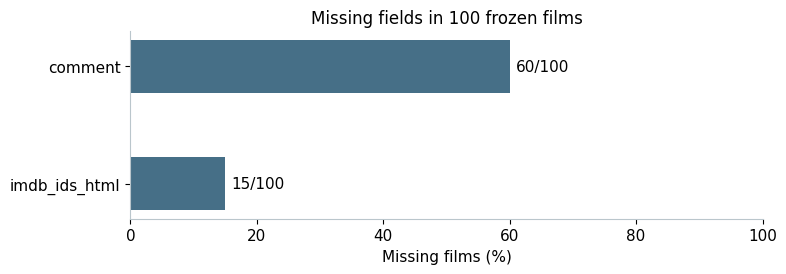

In [3]:
# Extremes select real cases, not an outlier-detection method.
extreme_films = main_films.loc[main_films.asl_seconds.isin([main_films.asl_seconds.min(), main_films.asl_seconds.max()])].copy()
extreme_films["ASL - MSL (s)"] = extreme_films.asl_seconds - extreme_films.msl_seconds
case_table = extreme_films[["tmdb_id", "page_id", "title", "release_year", "asl_seconds", "msl_seconds", "ASL - MSL (s)"]].merge(
    selected_rows[["tmdb_id", "page_id", "comment", "identity_check", "edition_check"]], on=["tmdb_id", "page_id"], validate="one_to_one")
case_fields = ["title", "release_year", "asl_seconds", "msl_seconds", "ASL - MSL (s)"]
display(case_table.sort_values("asl_seconds")[case_fields].rename(columns={
    "title": "Film", "release_year": "Year", "asl_seconds": "ASL (s)", "msl_seconds": "MSL (s)"
}).round(2))
def is_empty(value):
    return value is None or (isinstance(value, float) and math.isnan(value)) or (isinstance(value, str) and not value.strip()) or (isinstance(value, (list, dict)) and not value)
missing_rows = []
for field in passport["field_dictionary"]:
    test = (lambda v: v is None) if field == "review_reasons" else is_empty
    a = sum(test(v) for v in selected_rows[field])
    b = sum(test(v) for v in measurements[field])
    assert math.isclose(b / 505, passport["field_dictionary"][field]["missing_rate"], abs_tol=1e-12)
    missing_rows.append([field, a, a/100, b, b/505])
missing_table = pd.DataFrame(missing_rows, columns=["field", "missing_films", "missing_rate", "missing_measurements", "measurement_missing_rate"])
core = ["shot_count", "asl_seconds", "msl_seconds", "measured_seconds"]
display(missing_table.loc[missing_table.missing_films.gt(0) | missing_table.field.isin(core)].round(4))
missing_fields = missing_table.loc[missing_table.missing_films.gt(0)].sort_values("missing_rate")
fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(missing_fields.field, missing_fields.missing_rate * 100, height=0.45, color=palette["blue"])
for bar, count in zip(bars, missing_fields.missing_films):
    ax.text(bar.get_width()+1, bar.get_y()+bar.get_height()/2, f"{count}/100", va="center")
ax.set(title="Missing fields in 100 frozen films", xlabel="Missing films (%)", xlim=(0,100))
save_plot(fig, "fig06.png")


### M2.5 Where are optional page fields missing?
Use one selected page per film. Count missing IMDb links and contributor notes by decade and by the three Q2 genres. Genre groups overlap. Vote counts come from the TMDB candidate list, which required at least 1,000 votes.

- Missing IMDb links rise from 1/20 films in the 1970s to 6/20 in the 2010s. Adventure has 3/33 links missing and Drama has 8/37. Missing notes show a different pattern: 15/20 films in the 1970s and 11/20 in the 2010s.
- Median votes are higher for films without a recorded link (18,432 versus 15,404). For missing versus present notes, the medians are 15,816 and 16,870.5. Both comparisons have overlapping middle halves.
- These contrasts describe coverage in the selected sample. They do not establish a missingness mechanism. Leave the optional fields blank and retain the measured films.

In [4]:
keys = ["tmdb_id", "page_id"]
source_fields = ["imdb_ids_html", "comment", "vote_count"]
coverage = main_films[keys + ["decade", "genres"]].merge(
    selected_rows[keys + source_fields], on=keys, validate="one_to_one"
)
assert len(coverage) == len(main_films) == 100
assert coverage.tmdb_id.is_unique and coverage.page_id.is_unique
assert coverage.vote_count.ge(1000).all()
coverage["link_missing"] = coverage.imdb_ids_html.map(is_empty)
coverage["note_missing"] = coverage.comment.map(is_empty)

def missing_by(frame, group):
    table = frame.groupby(group).agg(films=("tmdb_id", "size"), links_missing=("link_missing", "sum"),
                                     notes_missing=("note_missing", "sum"))
    if group == "decade":
        table.loc["Total"] = table.sum()
    table["links_missing_%"] = (100 * table.links_missing / table.films).round(1)
    table["notes_missing_%"] = (100 * table.notes_missing / table.films).round(1)
    return table[["films", "links_missing", "links_missing_%", "notes_missing", "notes_missing_%"]]

by_decade = missing_by(coverage, "decade")
assert by_decade.loc[decade_order, "films"].eq(20).all()
totals = missing_table.set_index("field").missing_films
assert by_decade.loc["Total", "links_missing"] == totals["imdb_ids_html"]
assert by_decade.loc["Total", "notes_missing"] == totals["comment"]
display(by_decade)

# Each film counts once within each genre.
memberships = coverage.explode("genres").drop_duplicates(["tmdb_id", "genres"])
by_genre = missing_by(memberships, "genres").loc[["Adventure", "Drama", "Thriller"]]
display(by_genre)

vote_rows = []
for field, flag in [("IMDb link", "link_missing"), ("Contributor note", "note_missing")]:
    for missing, label in [(True, "Missing"), (False, "Present")]:
        votes = coverage.loc[coverage[flag].eq(missing), "vote_count"]
        vote_rows.append([field, label, len(votes), votes.median(), votes.quantile(0.25), votes.quantile(0.75)])
vote_summary = pd.DataFrame(vote_rows, columns=["Page field", "Status", "Films", "Median votes", "Q1", "Q3"])
display(vote_summary)
print("Films missing both fields:", (coverage.link_missing & coverage.note_missing).sum(), "/", len(coverage))

,films,links_missing,links_missing_%,notes_missing,notes_missing_%
decade,,,,,
1970s,20,1,5.0,15,75.0
1980s,20,2,10.0,10,50.0
1990s,20,3,15.0,10,50.0
2000s,20,3,15.0,14,70.0
2010s,20,6,30.0,11,55.0
Total,100,15,15.0,60,60.0


,films,links_missing,links_missing_%,notes_missing,notes_missing_%
genres,,,,,
Adventure,33,3,9.1,21,63.6
Drama,37,8,21.6,22,59.5
Thriller,27,5,18.5,15,55.6


,Page field,Status,Films,Median votes,Q1,Q3
0,IMDb link,Missing,15,18432.0,14270.50,25225.00
1,IMDb link,Present,85,15404.0,10513.00,21035.00
2,Contributor note,Missing,60,15816.0,11528.00,21499.75
3,Contributor note,Present,40,16870.5,11269.75,21133.25


Films missing both fields: 10 / 100


In [5]:
# M2.4 | compare two flags on the same 100 film ASLs.
asl = main_films["asl_seconds"]
assert len(asl) == 100 and np.isfinite(asl).all()

# Week 2 gives the Z-score formula. Use common cutoffs for this audit.
iqr_multiplier, z_cutoff = 1.5, 3
q1, q3 = asl.quantile([0.25, 0.75], interpolation="linear")
iqr = q3 - q1
lower = q1 - iqr_multiplier * iqr
upper = q3 + iqr_multiplier * iqr
iqr_flag = (asl < lower) | (asl > upper)

# Use the population SD because this check covers the whole frozen set.
asl_sd = asl.std(ddof=0)
assert asl_sd > 0
z_score = (asl - asl.mean()) / asl_sd
z_flag = z_score.abs() > z_cutoff

flags = main_films[["title", "asl_seconds"]].rename(
    columns={"title": "Film", "asl_seconds": "ASL (s)"}
)
flags["Runtime ratio"] = main_films["duration_ratio"].round(3)
flags["IQR flag"] = iqr_flag
flags["Z-score flag"] = z_flag
both = iqr_flag & z_flag
print(f"IQR: {iqr_multiplier:g} × IQR, outside [{lower:.2f}, {upper:.2f}] s. Z-score: |z| > {z_cutoff} (ddof=0).")
print(f"IQR: {iqr_flag.sum()} films. Z-score: {z_flag.sum()}. Both: {both.sum()}.")
print(f"IQR only: {(iqr_flag & ~z_flag).sum()}. Z-score only: {(z_flag & ~iqr_flag).sum()}.")
# Match each flagged film to the contributor's own page note.
flagged = flags.loc[iqr_flag | z_flag].copy()
keys = main_films.loc[flagged.index, ["tmdb_id", "page_id"]]
notes = keys.merge(selected_rows[["tmdb_id", "page_id", "comment", "identity_check", "selection_status"]],
                   on=["tmdb_id", "page_id"], validate="one_to_one", sort=False)
flagged["Identity evidence"] = notes.identity_check.to_numpy()
flagged["Decision"] = notes.selection_status.to_numpy()
flagged["Source note"] = notes.comment.replace("", "No note on this page").to_numpy()
display(flagged.sort_values("ASL (s)", ascending=False).reset_index(drop=True))
print("All listed pages passed Collection's rounded ASL check. Keep these frozen selections; editions and cut boundaries remain unverified.")

# Check the source before deciding what to keep.
shining_index = main_films.index[main_films["tmdb_id"].eq(694)].item()
shining = main_films.loc[shining_index]
source_row = selected_rows.loc[selected_rows["tmdb_id"].eq(shining.tmdb_id)
                               & selected_rows["page_id"].eq(shining.page_id)].iloc[0]
print(f"The Shining ({shining.asl_seconds:.1f} s): IQR = {iqr_flag.loc[shining_index]}, "
      f"Z-score = {z_flag.loc[shining_index]}.")
print(f"Collection check: runtime ratio {shining.duration_ratio:.4f} is within 0.90–1.10. "
      f"{shining.measured_seconds:,.1f} s / {shining.shot_count} shots = "
      f"{shining.measured_seconds / shining.shot_count:.4f} s, consistent with the displayed ASL.")
print(f"Contributor note: {source_row.comment or 'none'}. Keep the film in Q1–Q3. "
      "The recorded checks pass, with the edition and measurement boundaries still to verify.")

IQR: 1.5 × IQR, outside [0.10, 9.90] s. Z-score: |z| > 3 (ddof=0).
IQR: 9 films. Z-score: 1. Both: 1.
IQR only: 8. Z-score only: 0.


,Film,ASL (s),Runtime ratio,IQR flag,Z-score flag,Identity evidence,Decision,Source note
0,The Shining,69.8,0.970,True,True,IMDb + year,selected,No note on this page
1,Gravity,25.2,0.914,True,False,IMDb + year,selected,Analyzed from Blu-ray 3D. 2013 Academy Award w...
2,Chinatown,16.0,0.989,True,False,IMDb + year,selected,Chinatown Directed by Roman Polanski in 1974: ...
3,Barry Lyndon,15.7,0.956,True,False,IMDb + year,selected,No note on this page
4,Annie Hall,15.2,0.980,True,False,IMDb + year,selected,No note on this page
5,A Clockwork Orange,11.4,0.956,True,False,IMDb + year,selected,Includes main and end titles.
6,Full Metal Jacket,10.9,0.923,True,False,IMDb + year,selected,No note on this page
7,Reservoir Dogs,10.2,0.952,True,False,IMDb + year,selected,No note on this page
8,Young Frankenstein,10.0,0.997,True,False,IMDb + year,selected,No note on this page


All listed pages passed Collection's rounded ASL check. Keep these frozen selections; editions and cut boundaries remain unverified.
The Shining (69.8 s): IQR = True, Z-score = True.
Collection check: runtime ratio 0.9700 is within 0.90–1.10. 8,380.5 s / 120 shots = 69.8375 s, consistent with the displayed ASL.
Contributor note: none. Keep the film in Q1–Q3. The recorded checks pass, with the edition and measurement boundaries still to verify.


### M2.6-M2.7 Duplicate pages and their impact
- Reuse the same films and compare one selected page per film with all passing pages.
- Film_Collection shows the American Beauty page choice. M3.6 shows the identity review.

**Comparison chart.** How does counting all passing pages change decade ASL medians?
The nine flagged films passed Collection's source arithmetic and runtime checks. Their editions remain unverified. The long right tail raises the mean and standard deviation, so the Z-score cutoff flags fewer films than the quartile rule. Counting every passing page also gives more weight to films with several measurements.
Exact page repeats use page ID. Multiple pages with one TMDB ID count as repeat measurements, even when both pages pass.
M3.6 counts title-and-duration matches, checks film identity and shows two examples. Separate contributions can describe different edits of the same film.

Repeated page IDs: 0/505 rows. Films with several pages: 101/160 films.


,film_count,passing_page_count,all_passing_page_median_seconds,q1_median_seconds,difference_seconds
decade,,,,,
1970s,20,35,11.30,6.70,4.60
1980s,20,33,4.80,4.80,0.00
1990s,20,27,6.20,4.75,1.45
2000s,20,24,3.85,3.90,-0.05
2010s,20,27,3.80,3.85,-0.05


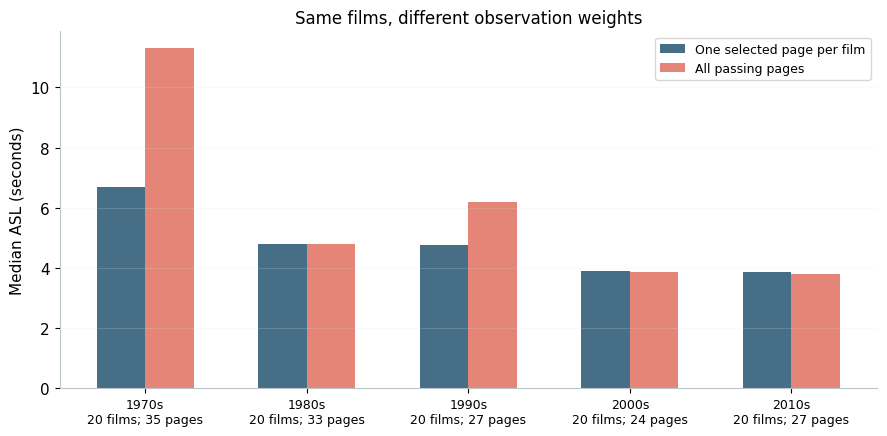

In [6]:
# Same films, different weights: compare one page per film with all passing pages.
page_counts = measurements.groupby("tmdb_id").size()
print(f"Repeated page IDs: {measurements.page_id.duplicated().sum()}/{len(measurements)} rows. Films with several pages: {(page_counts > 1).sum()}/{len(page_counts)} films.")
rhythm_fields = ["tmdb_id", "page_id", "decade", "asl_seconds", "msl_seconds", "shot_count", "measured_seconds"]
rhythm_films = main_films.loc[:, rhythm_fields].copy()
decade_summary = rhythm_films.groupby("decade").agg(
    film_count=("tmdb_id", "size"),
    asl_median_seconds=("asl_seconds", "median"),
    msl_median_seconds=("msl_seconds", "median"),
    asl_q1_seconds=("asl_seconds", lambda x: x.quantile(0.25, interpolation="linear")),
    asl_q3_seconds=("asl_seconds", lambda x: x.quantile(0.75, interpolation="linear"))
).reindex(decade_order)
assert decade_summary["film_count"].eq(20).all()
rhythm_summary = decade_summary[["film_count", "asl_median_seconds", "msl_median_seconds"]]
assert rhythm_films.tmdb_id.is_unique and rhythm_summary.film_count.eq(20).all()
q1_table = rhythm_summary.reset_index()
repeat_pages = measurements.loc[measurements.tmdb_id.isin(film_table.tmdb_id) & measurements.passes_initial_checks].copy()
assert repeat_pages.page_id.is_unique and set(repeat_pages.tmdb_id) == set(film_table.tmdb_id)
repeat_summary = repeat_pages.groupby("decade").agg(
    film_count=("tmdb_id", "nunique"), passing_page_count=("page_id", "size"),
    all_passing_page_median_seconds=("asl_seconds", "median")).reindex(decade_order)
repeat_summary["q1_median_seconds"] = decade_summary.asl_median_seconds
repeat_summary["difference_seconds"] = repeat_summary.all_passing_page_median_seconds - repeat_summary.q1_median_seconds
display(repeat_summary.round(2))

x = np.arange(len(decade_order))
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - 0.15, repeat_summary["q1_median_seconds"], width=0.30, color=palette["blue"], label="One selected page per film")
ax.bar(x + 0.15, repeat_summary["all_passing_page_median_seconds"], width=0.30, color=palette["coral"], label="All passing pages")
labels = []
for decade, row in repeat_summary.iterrows():
    labels.append(f"{decade}\n20 films; {int(row['passing_page_count'])} pages")
ax.set_xticks(x, labels, fontsize=9)
ax.set(title="Same films, different observation weights", ylabel="Median ASL (seconds)", ylim=(0, None))
ax.legend()
ax.grid(axis="y", alpha=0.2)
save_plot(fig, "fig05.png")

## M3 Prepare data and text
### M3.1-M3.2 Inputs, aggregation and sample
Prepare text inputs once before the numbered checks that use them. The decade summary from M2.7 is displayed in M6; all 100 frozen films are used without further subsampling. The original candidate acquisition is purposive, not random.

In [7]:
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Each overview is one document.
texts = main_films.sort_values("tmdb_id").reset_index(drop=True)
overview_audit = json.loads((root / "03_methods/text/overview_audit.json").read_text(encoding="utf-8"))
assert overview_audit["source_sha256"] == version["source_sha256"]
assert sorted((r["tmdb_id"], r["page_id"], r["overview"]) for r in overview_audit["films"]) == sorted(texts[["tmdb_id", "page_id", "overview_details"]].itertuples(index=False, name=None))

def tokenize(text):
    # Lowercase English letters; keep internal apostrophes; split hyphens.
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower().replace("\u2019", "'"))

stemmer = SnowballStemmer("english", ignore_stopwords=False)
stop_stems = {stemmer.stem(token) for word in ENGLISH_STOP_WORDS for token in tokenize(word)}
tokens = texts["overview_details"].map(tokenize).tolist()
stems = [[stemmer.stem(word) for word in document] for document in tokens]
final_tokens = [[word for word in document if word not in stop_stems] for document in stems]
assert len(final_tokens) == 100 and all(final_tokens)
assert all(not set(document) & stop_stems for document in final_tokens)

token_bytes = (root / "03_methods/text/processed_documents.json").read_bytes()
token_sha256 = hashlib.sha256(token_bytes).hexdigest()
prior_tokens = json.loads(token_bytes)
documents = prior_tokens["documents"]
assert [(d["tmdb_id"], d["page_id"], d["tokens"]) for d in documents] == list(zip(texts.tmdb_id, texts.page_id, final_tokens))
assert prior_tokens["stop_stems"] == sorted(stop_stems)

import itertools
from scipy.sparse import load_npz
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.preprocessing import normalize
matrix_folder = root / "03_methods/text"
info = json.loads((matrix_folder / "matrix_info.json").read_text(encoding="utf-8"))
assert info["source_sha256"] == version["source_sha256"] and token_sha256 == info["token_file_sha256"]
vectorizer = CountVectorizer(analyzer=lambda tokens: tokens)
counts = vectorizer.fit_transform(final_tokens).tocsr()
words = vectorizer.get_feature_names_out()
assert words.tolist() == info["words"] and (counts - load_npz(matrix_folder / "count_matrix.npz")).nnz == 0


### M3.3 Compare bins
Compare three-bin discretisation methods. Compare equal-width and equal-frequency counts without dropping high values or rounding assignment boundaries.
A few long ASLs stretch equal-width bins and leave most films together. Quantile bins compare relative position; Q1 still reports medians in seconds.

In [8]:
asl = film_table["asl_seconds"]
assert asl.notna().all() and np.isfinite(asl).all() and asl.gt(0).all()

k = 3  # Use three bins for comparison.
width_edges = np.linspace(asl.min(), asl.max(), k + 1)
width, width_edges = pd.cut(asl, width_edges, include_lowest=True, retbins=True)
frequency, frequency_edges = pd.qcut(asl, k, duplicates="drop", retbins=True)
rows = []
for method, groups, edges in [("Equal width", width, width_edges),
                              ("Equal frequency", frequency, frequency_edges)]:
    bin_counts = groups.value_counts(sort=False)
    assert groups.notna().all() and bin_counts.sum() == 100
    for i, count in enumerate(bin_counts):
        left = "[" if i == 0 else "("
        bounds = f"{left}{float(edges[i])!r}, {float(edges[i + 1])!r}]"
        rows.append([method, k, len(edges) - 1, bounds, int(count)])
bin_table = pd.DataFrame(rows, columns=["Method", "Target groups", "Actual groups", "Bounds (s)", "Film count"])
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(bin_table)

,Method,Target groups,Actual groups,Bounds (s),Film count
0,Equal width,3,3,"[2.3, 24.8]",98
1,Equal width,3,3,"(24.8, 47.3]",1
2,Equal width,3,3,"(47.3, 69.8]",1
3,Equal frequency,3,3,"[2.3, 3.999999999999999]",33
4,Equal frequency,3,3,"(3.999999999999999, 5.499999999999998]",33
5,Equal frequency,3,3,"(5.499999999999998, 69.8]",34


### M3.4-M3.5 Scale text and check film features
- L2 gives each TF-IDF document unit length. Longer synopses can contain more words. L2 scales a whole document, whereas a Z-score scales each term across films and changes the meaning of zero. The dot product below checks the closest saved synopsis pair.
- M3.6's title and duration scores use their own ratios. Film measurements keep their units.
- Use decade to group films, duration ratio to check coverage, and the ASL–MSL gap to compare two summaries.

Decade bins hide differences within each decade. Runtime coverage uses a reference release which may differ from the measured cut. A positive ASL–MSL gap can reflect longer shots pulling up the mean; the gap alone cannot identify a specific shot.

In [9]:
# Show how dividing by the row length changes the Jaws word weight.
# L2 normalisation uses the full document vocabulary.
transformer = TfidfTransformer(norm=None, use_idf=True, smooth_idf=True, sublinear_tf=False)
raw_tfidf = transformer.fit_transform(counts)
tfidf = normalize(raw_tfidf, norm="l2", axis=1)
row_lengths = np.sqrt(np.asarray(raw_tfidf.multiply(raw_tfidf).sum(axis=1)).ravel())
assert np.allclose(np.asarray(tfidf.multiply(tfidf).sum(axis=1)).ravel(), 1)
# Use town for the before/after example.
jaws = next(i for i, d in enumerate(documents) if d["tmdb_id"] == 578)
town = list(words).index("town")
normalization_table = pd.DataFrame([
    ["Before L2", float(raw_tfidf[jaws, town]), float(row_lengths[jaws])],
    ["After L2", float(tfidf[jaws, town]), 1.0],
], columns=["Stage", "Jaws: town weight", "Jaws vector length"])
display(normalization_table.round(6))

# Check the strongest saved text match against the full document vectors.
similarity = json.loads((matrix_folder / "similarity_results.json").read_text(encoding="utf-8"))
assert similarity["source_sha256"] == version["source_sha256"] and similarity["token_file_sha256"] == token_sha256
pair = max(similarity["film_pairs"], key=lambda row: row["overview_cosine"])
positions = pd.Series(texts.index, index=texts.tmdb_id)
left, right = positions[pair["left_tmdb_id"]], positions[pair["right_tmdb_id"]]
score = tfidf[left].multiply(tfidf[right]).sum()
assert np.isclose(score, pair["overview_cosine"])
print(f'{pair["left_title"]} / {pair["right_title"]}: synopsis cosine {score:.3f}. Different film IDs.')

,Stage,Jaws: town weight,Jaws vector length
0,Before L2,4.005683,22.447963
1,After L2,0.178443,1.000000


Harry Potter and the Half-Blood Prince / Harry Potter and the Deathly Hallows: Part 1: synopsis cosine 0.306. Different film IDs.


In [10]:
features = main_films.copy()
year = pd.to_datetime(features["release_date"]).dt.year
assert year.eq(features["release_year"]).all()
assert ((year // 10 * 10).astype(str) + "s").eq(features["decade"]).all()
ratio = features["measured_seconds"] / (features["runtime_minutes"] * 60)
assert np.allclose(ratio, features["duration_ratio"], rtol=0, atol=1e-12)
assert ratio.between(0.90, 1.10).all()
assert features["msl_seconds"].gt(0).all() and np.isfinite(features["msl_seconds"]).all()
features["asl_msl_gap"] = features["asl_seconds"] - features["msl_seconds"]
assert np.isfinite(features["asl_msl_gap"]).all()
example = features.loc[features["tmdb_id"].eq(578)].iloc[0]  # Jaws (1975).
feature_table = pd.DataFrame([
    ["decade", "Floor year to nearest decade", "Category", "1975 → 1970s"],
    ["duration_ratio", "Measured seconds / reference seconds", "Ratio", f"Jaws: {example.duration_ratio:.4f}"],
    ["asl_msl_gap", "ASL − MSL", "Seconds", f"Jaws: {example.asl_msl_gap:.1f} s"]
], columns=["Field", "Calculation", "Unit", "Check"])
display(feature_table)

display(features[["duration_ratio", "asl_msl_gap"]].agg(["min", "median", "max"]).round(3))

,Field,Calculation,Unit,Check
0,decade,Floor year to nearest decade,Category,1975 → 1970s
1,duration_ratio,Measured seconds / reference seconds,Ratio,Jaws: 0.9782
2,asl_msl_gap,ASL − MSL,Seconds,Jaws: 3.2 s


,duration_ratio,asl_msl_gap
min,0.900,0.70
median,0.945,1.55
max,0.997,66.00


### M3.6 Find measurement pages for identity review
- From 505 pages, consider each pair once. Require the same recorded year and a shared lowercase title word.
- Score title Jaccard (intersection / union) and duration similarity (shorter / longer). Invalid durations stay missing.
- Review one American Beauty pair and one high-scoring pair with different film IDs. Verify using metadata IDs and recorded page checks.
- Common words can match unrelated films. Alternate titles or missing years can hide matches. Similar duration alone cannot establish identity.

Flag pairs with identical title word sets and a shorter duration at least 90% of the longer duration. Title equality removes weak common-word matches. The duration cutoff allows a modest timing difference and screens out many excerpts. These are review cutoffs, not a validated duplicate classifier.

In [11]:
# Score page pairs first, then use IDs to check what the scores mean.
def title_words(title):
    return set(re.findall(r"[a-z0-9]+", title.lower()))
def jaccard(left, right):
    union = left | right
    return len(left & right) / len(union) if union else 0.0
pages = measurements.sort_values("page_id").reset_index(drop=True)
page_words = pages.title_html.map(title_words)
years = pd.to_numeric(pages.year_html, errors="coerce")
durations = pd.to_numeric(pages.measured_seconds, errors="coerce")
durations = durations.where(np.isfinite(durations) & durations.gt(0))
page_candidates = []
for i, j in itertools.combinations(range(len(pages)), 2):
    if pd.isna(years[i]) or pd.isna(years[j]) or years[i] != years[j] or not page_words[i] & page_words[j]:
        continue
    a, b = durations[i], durations[j]
    ratio = min(a,b)/max(a,b) if pd.notna(a) and pd.notna(b) else np.nan
    page_candidates.append([i,j,jaccard(page_words[i],page_words[j]),ratio])
assert len(page_candidates) == 1567
possible_pairs = math.comb(len(pages), 2)
print(f"Candidate pairs for review: {len(page_candidates):,}/{possible_pairs:,} ({len(page_candidates)/possible_pairs:.2%}).")
scores = pd.DataFrame(page_candidates, columns=["left", "right", "title", "duration"])
display(scores[["title", "duration"]].quantile([0.25, 0.50, 0.75]).round(3))
# First screen the measurements without using film IDs.
flags = scores[scores["title"].eq(1) & scores["duration"].ge(0.90)]
identity_counts = {"Same film IDs and year": 0, "Different TMDB IDs": 0, "Identity unresolved": 0}
for left, right in flags[["left", "right"]].itertuples(index=False, name=None):
    a, b = pages.iloc[left], pages.iloc[right]
    if a.tmdb_id != b.tmdb_id:
        group = "Different TMDB IDs"
    elif pd.notna(a.imdb_id) and bool(a.imdb_id) and a.imdb_id == b.imdb_id and a.year_html == b.year_html:
        group = "Same film IDs and year"
    else:
        group = "Identity unresolved"
    identity_counts[group] += 1
print(f"Flagged for review: {len(flags)}/{len(scores)} candidates ({len(flags)/len(scores):.2%}); "
      f"{len(flags)}/{possible_pairs:,} possible pairs ({len(flags)/possible_pairs:.2%}).")
display(pd.Series(identity_counts, name="Flagged pairs").to_frame())
# Only after scoring, use IDs and recorded page checks to verify candidates.
beauty = next(c for c in page_candidates if pages.loc[c[0],"title_html"] == pages.loc[c[1],"title_html"] == "American Beauty"
              and pages.loc[c[0],"passes_initial_checks"] and pages.loc[c[1],"passes_initial_checks"])
other = next(c for c in sorted(page_candidates,key=lambda c:-c[2]) if pages.loc[c[0],"tmdb_id"] != pages.loc[c[1],"tmdb_id"])
review_rows = []
for i,j,title_score,time_score in [beauty,other]:
    a,b = pages.iloc[i],pages.iloc[j]
    same_ids = a.tmdb_id == b.tmdb_id and bool(a.imdb_id) and a.imdb_id == b.imdb_id
    same_year = a.year_html == b.year_html
    classification = "Repeated measurement" if same_ids and same_year else "Different films"
    reason = f"{a.year_html} / {b.year_html}; TMDB {a.tmdb_id} / {b.tmdb_id}; IMDb {a.imdb_id} / {b.imdb_id}"
    review_rows.append([a.title_html, a.page_id, b.title_html, b.page_id, title_score, time_score,
                        same_ids, classification, reason])
page_review = pd.DataFrame(review_rows, columns=["Candidate A", "Page A", "Candidate B", "Page B",
                           "Title Jaccard", "Duration similarity", "Same IDs?", "Classification", "Reason"])
display(page_review.drop(columns=["Page A", "Page B"]).round(3))

Candidate pairs for review: 1,567/127,260 (1.23%).


,title,duration
0.25,1.0,0.072
0.50,1.0,0.351
0.75,1.0,0.967


Flagged for review: 493/1567 candidates (31.46%); 493/127,260 possible pairs (0.39%).


,Flagged pairs
Same film IDs and year,493
Different TMDB IDs,0
Identity unresolved,0


,Candidate A,Candidate B,Title Jaccard,Duration similarity,Same IDs?,Classification,Reason
0,American Beauty,American Beauty,1.000,0.999,True,Repeated measurement,1999 / 1999; TMDB 14 / 14; IMDb tt0169547 / tt...
1,The Matrix,The Mummy,0.333,0.809,False,Different films,1999 / 1999; TMDB 603 / 564; IMDb tt0133093 / ...


### M3.7 Process the English synopses
Use one checked overview per frozen film: lowercase tokenisation, English Snowball stemming, then stop-word removal. Apply the same tokenizer and stemmer to the stop-word list. Show one real Jaws sentence and the distinct vocabulary size after each step. Stems need not be dictionary words: strikes becomes strike and community becomes communiti. The complete ordered token lists retain repeated words for counting.


In [12]:
# One sentence illustrates the same pipeline used for all films.
jaws_text = texts.loc[jaws, "overview_details"]  # This overview is one sentence.
print("Jaws original:", jaws_text)
for label, stage in [("1. Tokens", tokens), ("2. Stems", stems), ("3. Without stop words", final_tokens)]:
    print(label + ":", " ".join(stage[jaws]))
vocabulary_table = pd.DataFrame([
    [label, len({word for document in stage for word in document})]
    for label, stage in [("Tokenize", tokens), ("Stem", stems), ("Remove stop words", final_tokens)]
], columns=["Stage", "Vocabulary size"])
assert vocabulary_table["Vocabulary size"].is_monotonic_decreasing
display(vocabulary_table)

Jaws original: When the seaside community of Amity finds itself under attack by a dangerous great white shark, the town's chief of police, a young marine biologist, and a grizzled shark hunter embark on a desperate quest to kill the beast before it strikes again.
1. Tokens: when the seaside community of amity finds itself under attack by a dangerous great white shark the town's chief of police a young marine biologist and a grizzled shark hunter embark on a desperate quest to kill the beast before it strikes again
2. Stems: when the seasid communiti of amiti find itself under attack by a danger great white shark the town chief of polic a young marin biologist and a grizzl shark hunter embark on a desper quest to kill the beast befor it strike again
3. Without stop words: seasid communiti amiti attack danger great white shark town chief polic young marin biologist grizzl shark hunter embark desper quest kill beast strike


,Stage,Vocabulary size
0,Tokenize,1983
1,Stem,1722
2,Remove stop words,1545


### M3.8 Compare word counts and TF IDF weights
Keep the full count and TF-IDF matrices: 100 films by 1,545 words. Frequency Top20 ranks total occurrences; TF-IDF Top20 ranks sums of L2-normalised document weights. Both use alphabetical tie-breaking. Report matrix shape, nonzero ratio and sparsity without printing the full matrix.

Use raw count TF, smooth IDF = ln((N + 1)/(df + 1)) + 1, then divide each weighted document by its full L2 norm. For Jaws, shark occurs twice in one of 100 documents. The reference retains the full-vocabulary denominator and matrix value. Rare character names can rise under IDF, and the s fragment shows that abbreviation noise remains; the keywords do not automatically represent editing rhythm.

#### TF-IDF calculation: shark in Jaws
Raw TF = 2, DF = 1, N = 100. The code uses smooth IDF, no sublinear TF and full-row L2 normalisation.

1. IDF = 1 + ln((100 + 1)/(1 + 1)) = **4.921973336281**.
2. Unnormalised weight = 2 x IDF = **9.843946672563**.
3. The full 1,545-word Jaws vector has L2 length **22.447962627389**.
4. Normalised weight = 9.843946672563 / 22.447962627389 = **0.438522944641**.

The denominator includes every nonzero term in this document. Compare with row 34, column 1226 of the full sklearn matrix, before feature selection.

In [13]:
# Show the two Top 20 lists, then check shark against the full sklearn matrix.
# Rank corpus column sums; break ties alphabetically.
total_counts = np.asarray(counts.sum(axis=0)).ravel()
document_counts = np.asarray(counts.getnnz(axis=0)).ravel()
tfidf_sums = np.asarray(tfidf.sum(axis=0)).ravel()
frequency_order = sorted(range(len(words)), key=lambda j: (-int(total_counts[j]), words[j]))
tfidf_order = sorted(range(len(words)), key=lambda j: (-float(tfidf_sums[j]), words[j]))
ranking_table = pd.DataFrame([
    [rank + 1, words[a], int(total_counts[a]), int(document_counts[a]), words[b], float(tfidf_sums[b])]
    for rank, (a, b) in enumerate(zip(frequency_order[:20], tfidf_order[:20]))
], columns=["Rank", "Word by count", "Count", "Films", "Word by TF-IDF", "Weight"])
display(ranking_table.round(3))
matrix_table = pd.DataFrame([
    [name, matrix.shape[0], matrix.shape[1], matrix.nnz,
     matrix.nnz / (matrix.shape[0] * matrix.shape[1]),
     1 - matrix.nnz / (matrix.shape[0] * matrix.shape[1])]
    for name, matrix in [("Counts", counts), ("TF-IDF", tfidf)]
], columns=["Matrix", "Films", "Words", "Nonzero cells", "Nonzero ratio", "Sparsity"])
prior_tfidf = load_npz(matrix_folder / "tfidf_matrix.npz")
assert prior_tfidf.shape == tfidf.shape
assert np.allclose((prior_tfidf - tfidf).data, 0, rtol=0, atol=1e-12)
assert counts.shape == tfidf.shape and counts.nnz == tfidf.nnz
display(matrix_table.round(4))

# Full-vocabulary reference for the Jaws term calculation.
shark = list(words).index("shark")
shark_reference = pd.DataFrame([{
    "tmdb_id": documents[jaws]["tmdb_id"], "row_index": jaws, "column_index": shark,
    "tf": int(counts[jaws, shark]), "df": int(counts[:, shark].getnnz()), "documents": counts.shape[0],
    "full_row_l2": float(row_lengths[jaws]), "matrix_value": float(tfidf[jaws, shark])
}])
assert int(shark_reference.iloc[0]["tf"]) == info["shark_check"]["jaws_count"]
assert int(shark_reference.iloc[0]["df"]) == info["shark_check"]["column_nonzero_rows"]
# Compare the written calculation with sklearn, using unrounded inputs.
written_idf = 1 + math.log((1 + counts.shape[0]) / (1 + counts[:, shark].getnnz()))
written_weight = int(counts[jaws, shark]) * written_idf / row_lengths[jaws]
assert math.isclose(written_weight, float(tfidf[jaws, shark]), rel_tol=0, abs_tol=1e-12)
print(f"shark: calculation and sklearn agree at {float(tfidf[jaws, shark]):.9f}.")

,Rank,Word by count,Count,Films,Word by TF-IDF,Weight
0,1,life,20,16,life,2.440
1,2,world,20,18,world,2.041
2,3,new,14,12,young,1.841
3,4,war,13,12,new,1.752
4,5,young,13,12,harri,1.637
5,6,crime,12,10,war,1.617
6,7,live,12,11,crime,1.613
7,8,harri,11,5,turn,1.487
8,9,turn,11,10,live,1.432
9,10,year,11,10,school,1.419


,Matrix,Films,Words,Nonzero cells,Nonzero ratio,Sparsity
0,Counts,100,1545,2469,0.016,0.984
1,TF-IDF,100,1545,2469,0.016,0.984


shark: calculation and sklearn agree at 0.438522945.


### M3.9 Variance-based feature selection for synopsis text
For each term, compare its L2-normalised TF-IDF weight across all 100 films, including zeros. Higher population variance means the term varies more between descriptions. This unsupervised selection uses no editing-rhythm target. Keep the original 300 terms with alphabetical ties.

Selection keeps named terms; extracting latent components would combine terms and require a fitted model. This is a dimension-reduction check only. The full vocabulary supplies the earlier shark and cosine checks; Q1–Q3 still use the film-level ASL and MSL.

In [14]:
# Compare term variance across the same 100 documents.
selection = json.loads((matrix_folder / "run_info.json").read_text(encoding="utf-8"))
mean = np.asarray(tfidf.mean(axis=0)).ravel()
variance = np.maximum(0, np.asarray(tfidf.multiply(tfidf).mean(axis=0)).ravel() - mean ** 2)
chosen = np.array(sorted(range(len(words)), key=lambda j: (-float(variance[j]), words[j]))[:300])
reduced = tfidf[:, chosen].tocsr()
assert chosen.tolist() == selection["selected_column_indices"]
saved_text = load_npz(matrix_folder / "selected_tfidf_matrix.npz")
assert selection["source_sha256"] == version["source_sha256"] and words[chosen].tolist() == selection["selected_words"]
assert reduced.shape == saved_text.shape and np.allclose((reduced - saved_text).data, 0)
print(f"Films × terms: {tfidf.shape} → {reduced.shape}. First five terms: {', '.join(words[chosen[:5]])}.")

Films × terms: (100, 1545) → (100, 300). First five terms: harri, life, mr, sir, school.


## M4 Explore genre combinations
### M4.1 Run Apriori and verify the five film example
One film is one genre-set transaction. Execute the same 10-film support setting and explicit zero confidence threshold; compare all rule metrics with the original saved experiment. The five-film case uses two of five films as its threshold. Check the algorithm against an independent enumeration.

#### Independent enumeration of the five displayed transactions
The transactions are Drama; Action/Crime; Science Fiction/Drama/Romance; Adventure/Fantasy/Action; Drama.

| Singleton | Film count | Support |
| --- | ---: | ---: |
| Drama | 3 | 3/5 = 0.6 |
| Action | 2 | 2/5 = 0.4 |
| Crime, Science Fiction, Romance, Adventure, Fantasy | 1 each | 1/5 = 0.2 each |

Enumerate all subsets: the two three-label transactions each supply three pairs and one triple; the Action/Crime transaction supplies one pair. None of these seven pairs or two triples repeats. No transaction has four labels. At count 2, only the singleton sets Drama and Action pass. Compare these counts and sets with the Apriori table below; matching outputs check for missing and extra itemsets. This check is separate from the full-sample rule metrics and six-point timing experiment.

The cells below compare the reference enumeration and library results, then check full-sample metrics.

In [15]:
# Show the five-film Apriori check and the full-sample rule count.
from mlxtend.frequent_patterns import apriori, association_rules
m4_dir = root / "03_methods/association"
m4_info = json.loads((m4_dir / "run_info.json").read_text(encoding="utf-8"))
m4_rule_info = json.loads((m4_dir / "association_rules.json").read_text(encoding="utf-8"))
assert m4_info["source_sha256"] == m4_rule_info["source_sha256"] == version["source_sha256"]
# Match the original sweep: one row per frozen film, in TMDB ID order.
assert m4_info["table_sha256"] == version["table_sha256"]
assert m4_info["candidate_sha256"] == m4_rule_info["candidate_sha256"] == pool_sha256
genres_by_id = main_films.set_index("tmdb_id").genres.sort_index()
labels = sorted({label for genres in genres_by_id for label in genres})
basket = pd.DataFrame({label: genres_by_id.map(lambda genres: label in genres) for label in labels})
assert basket.shape == (m4_info["film_count"], m4_info["genre_count"])
frequent = apriori(basket, min_support=0.10, use_colnames=True)
live_rules = association_rules(frequent, num_itemsets=100, metric="confidence", min_threshold=0.0)
live_rules["rule"] = live_rules.apply(lambda r: " + ".join(sorted(r.antecedents)) + " -> " + " + ".join(sorted(r.consequents)), axis=1)
reference_rules = pd.DataFrame(m4_rule_info["rules"]).set_index("rule")
assert len(frequent) == 17 and len(live_rules) == 20
assert np.allclose(live_rules.set_index("rule").loc[reference_rules.index, ["support","confidence","lift"]], reference_rules[["support","confidence","lift"]])
m4_five = main_films.sort_values("tmdb_id").head(5)[["tmdb_id","title","genres"]]
display(m4_five)
five_items = apriori(basket.loc[m4_five.tmdb_id], min_support=0.4, use_colnames=True)
assert set(five_items.itemsets) == {frozenset(["Drama"]), frozenset(["Action"])}
display(five_items)


,tmdb_id,title,genres
40,14,American Beauty,[Drama]
60,24,Kill Bill: Vol. 1,"[Action, Crime]"
61,38,Eternal Sunshine of the Spotless Mind,"[Science Fiction, Drama, Romance]"
62,58,Pirates of the Caribbean: Dead Man's Chest,"[Adventure, Fantasy, Action]"
41,73,American History X,[Drama]


,support,itemsets
0,0.4,(Action)
1,0.6,(Drama)


### M4.2-M4.3 Core reference and metrics
- Support is the joint count divided by 100. Confidence is the joint count divided by the antecedent count. Lift compares confidence with the consequent's overall share.
- Adventure occurs in 33% of the sample. For Action → Adventure, compare that baseline with 46.7% confidence.
- M4.4 reruns the six thresholds and checks counts against the saved table.

**Diagnostic chart.** Where do the 20 rules sit by support, confidence and lift?
Apriori builds larger candidates from frequent smaller sets. A superset cannot occur in more films than its subsets, so a failed subset rules out every candidate containing it. The support cutoff filters itemsets; the confidence cutoff filters directions. Genre overlap helps explain why Q2 groups share films.

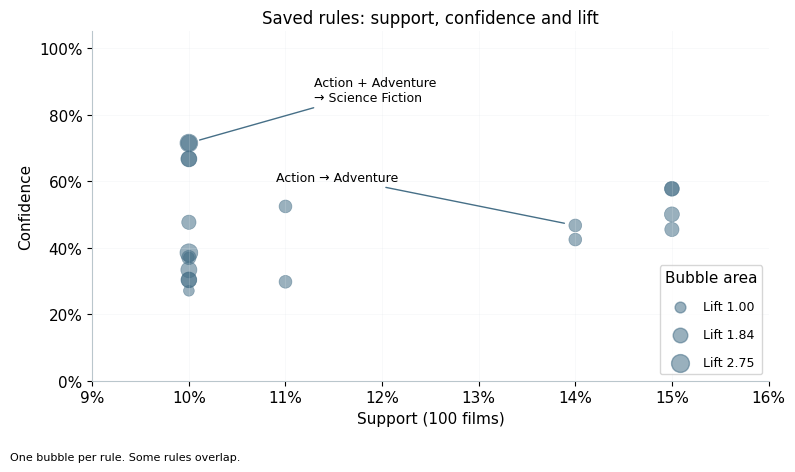

In [16]:
m4_rules = pd.DataFrame(m4_rule_info["rules"])
assert m4_rule_info["minimum_film_count"] == 10
m4_columns = ["rule", "joint_film_count", "support", "confidence", "lift", "consequent_support"]

from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(8, 5))
rule_points = ax.scatter(m4_rules["support"], m4_rules["confidence"], s=m4_rules["lift"] * 60,
                         color=palette["blue"], alpha=0.55, edgecolors=palette["blue"], linewidths=0.5)
assert len(rule_points.get_offsets()) == len(m4_rules) == 20
assert np.allclose(rule_points.get_sizes() / m4_rules["lift"], 60)
for lift_value in [m4_rules["lift"].min(), m4_rules["lift"].median(), m4_rules["lift"].max()]:
    ax.scatter([], [], s=lift_value * 60, color=palette["blue"], alpha=0.55, label=f"Lift {lift_value:.2f}")
ax.set(title="Saved rules: support, confidence and lift", xlabel="Support (100 films)",
       ylabel="Confidence", xlim=(0.09, 0.16), ylim=(0, 1.05))
ax.set_xticks(np.arange(9, 17) / 100)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
for rule, label, position in [
    ("Action -> Adventure", "Action → Adventure", (0.109, 0.60)),
    ("Action + Adventure -> Science Fiction", "Action + Adventure\n→ Science Fiction", (0.113, 0.84)),
]:
    point = m4_rules.loc[m4_rules.rule.eq(rule)].iloc[0]
    ax.annotate(label, (point.support, point.confidence), xytext=position, fontsize=9,
                arrowprops={"arrowstyle": "-", "color": palette["blue"], "shrinkB": 8})
ax.legend(title="Bubble area", loc="lower right", labelspacing=1.2)
ax.grid(alpha=0.2)
fig.text(0.01, 0.065, "One bubble per rule. Some rules overlap.", fontsize=8)
save_plot(fig, "fig09.png")

### M4.4 Run the six support thresholds
Use the same 100-film genre basket for all six calls. Divide each minimum film count by 100 to get its support proportion. Time only Apriori. Check the itemset counts against the original run saved in data_compact.zip.

**Diagnostic chart.** How do itemset count and runtime change as the threshold rises? Once a subset falls below support, its supersets can be pruned. The two axes have different units. Each runtime is a single measurement and can vary on the next run. The report figure preserves the original timing.

In [17]:
# Time only the Apriori call at each support level.
from time import perf_counter

MIN_COUNTS = [2, 5, 10, 15, 20, 30]
assert MIN_COUNTS == m4_info["minimum_counts"]

rows = []
for minimum in MIN_COUNTS:
    support = minimum / len(basket)
    start = perf_counter()
    itemsets = apriori(basket, min_support=support, use_colnames=True)
    elapsed = perf_counter() - start
    # Counting and recording are outside the timer.
    rows.append({
        "Minimum film count": minimum,
        "Frequent itemset count": len(itemsets),
        "Apriori runtime (s)": elapsed,
    })

table = pd.DataFrame(rows)
itemset_counts = table["Frequent itemset count"].tolist()
assert all(a >= b for a, b in zip(itemset_counts, itemset_counts[1:])), "Counts must not increase."
assert table.loc[table["Minimum film count"].eq(10), "Frequent itemset count"].item() == 17

# The saved table checks the counts. Times come from this run.
saved_thresholds = pd.read_json(m4_dir / "threshold_table.json")
count_fields = ["Minimum film count", "Frequent itemset count"]
pd.testing.assert_frame_equal(table[count_fields], saved_thresholds[count_fields])
display(table)

,Minimum film count,Frequent itemset count,Apriori runtime (s)
0,2,77,0.002281
1,5,40,0.001358
2,10,17,0.001182
3,15,8,0.001728
4,20,6,0.001550
5,30,3,0.000966


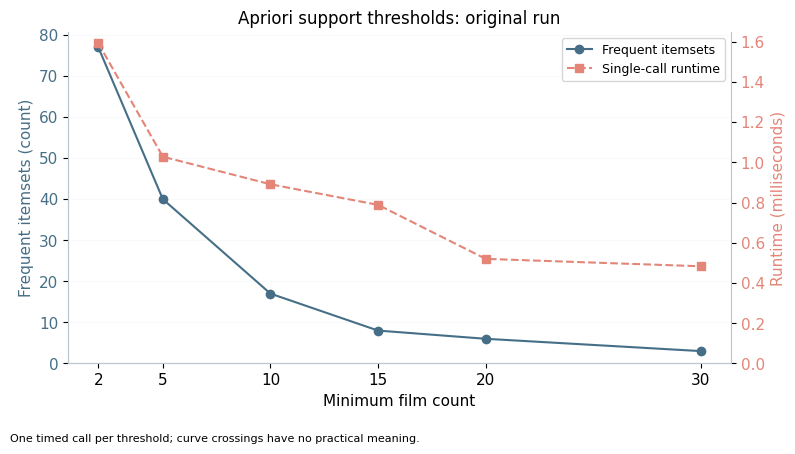

At minimum count 10: 17 frequent itemsets; 20 directed rules.


In [18]:
# Plot the archived timings for a consistent reference. The table above shows this run.
fig, count_axis = plt.subplots(figsize=(8, 4.8))
time_axis = count_axis.twinx()
time_axis.spines["right"].set_visible(True)
support_counts = saved_thresholds["Minimum film count"]
count_line = count_axis.plot(support_counts, saved_thresholds["Frequent itemset count"],
                             marker="o", color=palette["blue"], label="Frequent itemsets")
time_line = time_axis.plot(support_counts, saved_thresholds["Apriori runtime (s)"] * 1000,
                           marker="s", linestyle="--", color=palette["coral"], label="Single-call runtime")
count_axis.set(title="Apriori support thresholds: original run", xlabel="Minimum film count", ylim=(0, None))
count_axis.set_ylabel("Frequent itemsets (count)", color=palette["blue"])
time_axis.set_ylabel("Runtime (milliseconds)", color=palette["coral"])
time_axis.set_ylim(bottom=0)
count_axis.tick_params(axis="y", labelcolor=palette["blue"])
time_axis.tick_params(axis="y", labelcolor=palette["coral"])
count_axis.set_xticks(support_counts)
count_axis.legend(handles=count_line + time_line, loc="upper right", fontsize=9)
count_axis.grid(axis="y", alpha=0.2)
fig.text(0.01, 0.065, "One timed call per threshold; curve crossings have no practical meaning.", fontsize=8)
save_plot(fig, "fig08.png")


itemset_count = int(table.loc[table["Minimum film count"].eq(10), "Frequent itemset count"].item())
rule_count = len(m4_rule_info["rules"])
assert itemset_count == 17 and rule_count == 20
print("At minimum count 10:", itemset_count, "frequent itemsets;", rule_count, "directed rules.")

### M4.5–M4.6 Read the rules against their baselines
Adventure occurs in 33 films and is a Q2 comparison group. The tables show the ten highest lifts and all 12 Adventure rules, including reverse directions.

Lift is confidence divided by the overall share of the consequent. In the 20 saved rules, Thriller → Drama has 37.04% confidence against a 37% Drama baseline (lift 1.001). Its reverse has 27.03% confidence against 27%. Both are near independence. Action + Adventure → Science Fiction reaches 71.43% confidence against 26% (lift 2.747).

The fixed ten-film support setting produced no convincing example with both high confidence and lift near one. This limits the example available for M4.5.

Use the report’s ten-percent band around independence and a 50% confidence threshold (at least half the antecedent films). Confidence equals lift times consequent prevalence. A multi-genre consequent can be no more common than any one of its genres. M4.5 is partially satisfied.

In [19]:
m4_top10 = m4_rules[m4_columns].head(10).copy()
assert len(m4_top10) == 10
def show_rules(table):
    columns = ["rule", "joint_film_count", "support", "confidence", "lift"]
    labels = ["Rule", "Films", "Support", "Confidence", "Lift"]
    display(table[columns].set_axis(labels, axis=1).style.format({
        "Support": "{:.1%}", "Confidence": "{:.1%}", "Lift": "{:.3f}"
    }).hide(axis="index"))

show_rules(m4_top10)

m4_adventure = m4_rules.loc[m4_rules["rule"].str.contains(r"\bAdventure\b", regex=True), m4_columns].copy()
assert len(m4_adventure) == 12
show_rules(m4_adventure)
# Compare confidence with the largest possible consequent baseline.
high = m4_rules.confidence.ge(0.50)
near = m4_rules.lift.between(0.90, 1.10)
checks = {"Confidence ≥ 50%": high, "Lift within 10% of one": near, "Both conditions": high & near}
display(pd.DataFrame([[name, mask.sum(), ", ".join(m4_rules.loc[mask, "rule"]) or "None"]
                      for name, mask in checks.items()], columns=["Check", "Rules", "Matches"]))
coverage = basket.mean()
print(f"Largest genre baseline: {coverage.idxmax()} ({coverage.max():.0%}). "
      f"At lift ≤ 1.10, confidence ≤ {1.10 * coverage.max():.1%}.")


Rule,Films,Support,Confidence,Lift
Science Fiction -> Action + Adventure,10,10.0%,38.5%,2.747
Action + Adventure -> Science Fiction,10,10.0%,71.4%,2.747
Adventure + Science Fiction -> Action,10,10.0%,66.7%,2.222
Action -> Adventure + Science Fiction,10,10.0%,33.3%,2.222
Adventure -> Fantasy,10,10.0%,30.3%,2.165
Fantasy -> Adventure,10,10.0%,71.4%,2.165
Adventure -> Action + Science Fiction,10,10.0%,30.3%,2.020
Action + Science Fiction -> Adventure,10,10.0%,66.7%,2.020
Science Fiction -> Action,15,15.0%,57.7%,1.923
Action -> Science Fiction,15,15.0%,50.0%,1.923


Rule,Films,Support,Confidence,Lift
Science Fiction -> Action + Adventure,10,10.0%,38.5%,2.747
Action + Adventure -> Science Fiction,10,10.0%,71.4%,2.747
Adventure + Science Fiction -> Action,10,10.0%,66.7%,2.222
Action -> Adventure + Science Fiction,10,10.0%,33.3%,2.222
Adventure -> Fantasy,10,10.0%,30.3%,2.165
Fantasy -> Adventure,10,10.0%,71.4%,2.165
Adventure -> Action + Science Fiction,10,10.0%,30.3%,2.020
Action + Science Fiction -> Adventure,10,10.0%,66.7%,2.020
Science Fiction -> Adventure,15,15.0%,57.7%,1.748
Adventure -> Science Fiction,15,15.0%,45.5%,1.748


,Check,Rules,Matches
0,Confidence ≥ 50%,8,"Action + Adventure -> Science Fiction, Adventu..."
1,Lift within 10% of one,2,"Drama -> Thriller, Thriller -> Drama"
2,Both conditions,0,None


Largest genre baseline: Drama (37%). At lift ≤ 1.10, confidence ≤ 40.7%.


## M5 Group films with MapReduce
### M5.1 Map, shuffle, combine and reduce
Map emits (decade, (ASL, 1)) for each film. Shuffle collects the list for each decade. Reduce divides its sum by its film count. Combining within each ten-film block sends partial sums and counts so differently sized groups still contribute the right weight.

In [20]:
# Keep the original map, shuffle, combine and reduce functions.
from collections import defaultdict

GROUP_SIZE = 10


def map_films(films):
    # One value per film: ASL sum contribution and film count contribution.
    return [(film["decade"], (float(film["asl_seconds"]), 1)) for film in films]


def shuffle_records(records):
    # Group intermediate values by decade.
    groups = defaultdict(list)
    for decade, value in records:
        groups[decade].append(value)
    return groups


def combine_records(records):
    # Local aggregation sends sums and counts, never just group averages.
    groups = shuffle_records(records)
    return [(decade, (math.fsum(v[0] for v in values), sum(v[1] for v in values)))
            for decade, values in sorted(groups.items())]


def reduce_groups(groups):
    rows = []
    for decade, values in sorted(groups.items()):
        total = math.fsum(value[0] for value in values)
        count = sum(value[1] for value in values)
        rows.append({"Decade": decade, "Film count": count,
                     "MapReduce mean ASL (s)": total / count})
    return rows


def wire_bytes(records):
    # Explicit estimate: compact UTF-8 JSON per record plus one newline.
    # Includes key, sum and count; excludes protocol and Python object overhead.
    return sum(len((json.dumps(record, separators=(",", ":"), ensure_ascii=False)
                    + "\n").encode("utf-8")) for record in records)

### M5.2 Run the aggregation and check shuffle costs
Sort the 100 frozen films by TMDB ID. Use the original blocks of ten for the combiner. Compare the five decade means against pandas and count the records and bytes sent to shuffle. Q1 uses medians.

In [21]:
# Use one ASL per selected film, in the same order as the original run.
frame = film_table.copy()
q1 = decade_summary["asl_median_seconds"].to_dict()
films = frame.sort_values("tmdb_id").to_dict("records")

mapped = map_films(films)
shuffled = shuffle_records(mapped)
baseline = reduce_groups(shuffled)

# Deterministic groups of ten films in ascending TMDB ID order.
combined = []
for start in range(0, len(films), GROUP_SIZE):
    group = films[start:start + GROUP_SIZE]
    local = combine_records(map_films(group))
    combined.extend(local)
optimized = reduce_groups(shuffle_records(combined))
# Match by decade so row order cannot change the comparison.
raw = pd.DataFrame(baseline).set_index("Decade")
combined_result = pd.DataFrame(optimized).set_index("Decade")
check = frame.groupby("decade").asl_seconds.agg(["size", "mean", "median"])
for result in [raw, combined_result, check]:
    assert len(result) == 5 and result.index.is_unique
    assert set(result.index) == set(decade_order)

comparison = pd.DataFrame(index=pd.Index(decade_order, name="Decade"))
comparison["Raw N"] = raw["Film count"]
comparison["Combiner N"] = combined_result["Film count"]
comparison["Pandas N"] = check["size"]
assert comparison.eq(20).all().all()
mean_field = "MapReduce mean ASL (s)"
comparison["Raw mean (s)"] = raw[mean_field]
comparison["Combiner mean (s)"] = combined_result[mean_field]
comparison["Pandas mean (s)"] = check["mean"]
means = comparison[["Raw mean (s)", "Combiner mean (s)", "Pandas mean (s)"]]
assert np.isfinite(means).all().all()
# The range bounds every pairwise difference within a decade.
assert (means.max(axis=1) - means.min(axis=1)).le(1e-12).all()
assert np.allclose(check["median"].loc[decade_order], [q1[d] for d in decade_order], atol=1e-12, rtol=0)

cost = {"per_film_records": len(mapped), "per_film_bytes": wire_bytes(mapped),
        "combined_records": len(combined), "combined_bytes": wire_bytes(combined)}

mr_evidence = json.loads((root / "03_methods/mapreduce/evidence.json").read_text(encoding="utf-8"))
assert mr_evidence["source_sha256"] == version["source_sha256"]
assert mr_evidence["table_sha256"] == version["table_sha256"]
assert mr_evidence["group_size"] == GROUP_SIZE
original_ids = [uid for group in mr_evidence["local_groups"] for uid in group["film_ids"]]
assert original_ids == [film["tmdb_id"] for film in films]
assert cost == mr_evidence["cost"]
saved_means = pd.DataFrame(mr_evidence["optimized_result"]).set_index("Decade")[mean_field]
pd.testing.assert_series_equal(raw[mean_field].sort_index(), saved_means.sort_index(), check_exact=True)

display(pd.DataFrame(mapped[:5], columns=["Decade", "Map value (ASL, count)"]))
key = mapped[0][0]
print(f"Shuffle example: {key} has {len(shuffled[key])} values. First three: {shuffled[key][:3]}")
display(comparison.round(3))
display(pd.DataFrame([
    ["Per film", cost["per_film_records"], cost["per_film_bytes"]],
    ["Local sums and counts", cost["combined_records"], cost["combined_bytes"]]
], columns=["Method", "Shuffle records", "Estimated payload bytes"]))
print("M5 passed: same five unique decades, film counts and means in all three results.")

,Decade,"Map value (ASL, count)"
0,1990s,"(7.0, 1)"
1,2000s,"(3.9, 1)"
2,2000s,"(4.7, 1)"
3,2000s,"(3.3, 1)"
4,1990s,"(3.2, 1)"


Shuffle example: 1990s has 20 values. First three: [(7.0, 1), (3.2, 1), (6.9, 1)]


,Raw N,Combiner N,Pandas N,Raw mean (s),Combiner mean (s),Pandas mean (s)
Decade,,,,,,
1970s,20,20,20,8.080,8.080,8.080
1980s,20,20,20,8.325,8.325,8.325
1990s,20,20,20,5.475,5.475,5.475
2000s,20,20,20,4.245,4.245,4.245
2010s,20,20,20,4.805,4.805,4.805


,Method,Shuffle records,Estimated payload bytes
0,Per film,100,1809
1,Local sums and counts,35,698


M5 passed: same five unique decades, film counts and means in all three results.


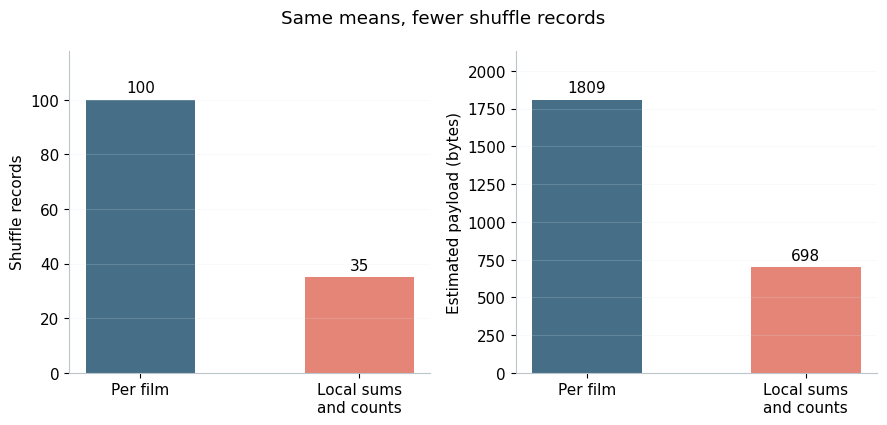

In [22]:
methods = ["Per film", "Local sums\nand counts"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.8))
values = [[cost["per_film_records"], cost["combined_records"]],
          [cost["per_film_bytes"], cost["combined_bytes"]]]
for ax, numbers, unit in zip(axes, values, ["Shuffle records", "Estimated payload (bytes)"]):
    bars = ax.bar(methods, numbers, width=0.5, color=[palette["blue"], palette["coral"]])
    ax.bar_label(bars, padding=3)
    ax.set(ylabel=unit, ylim=(0, max(numbers) * 1.18))
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Same means, fewer shuffle records")
save_plot(fig, "fig10.png")

### M5.3 Measure time and memory
Use the same 100 ordered films. Time seven runs of the ordinary map, shuffle and reduce path. Measure its Python allocations separately so tracing does not inflate the reported runtime. The estimate uses half of the RAM available at execution and assumes the same bytes per row. Streaming or a different key distribution can change this estimate.

In [23]:
from time import perf_counter
from statistics import median as trial_median
import tracemalloc
import psutil

two_columns = frame.sort_values("tmdb_id")[["decade", "asl_seconds"]]
input_bytes = int(two_columns.memory_usage(index=True, deep=True).sum())
times, peaks = [], []
for trial in range(7):
    # Include row conversion in the measured path.
    start = perf_counter()
    result = reduce_groups(shuffle_records(map_films(two_columns.to_dict("records"))))
    times.append(perf_counter() - start)
    assert result == baseline
    tracemalloc.start()
    try:
        reduce_groups(shuffle_records(map_films(two_columns.to_dict("records"))))
        peaks.append(tracemalloc.get_traced_memory()[1])
    finally:
        tracemalloc.stop()
peak = trial_median(peaks)
available = psutil.virtual_memory().available
# Illustrative capacity: resident input plus temporary Python allocations.
bytes_per_row = (input_bytes + peak) / len(two_columns)
row_budget = int(0.5 * available / bytes_per_row)
print(f"Measured: {len(two_columns)} rows, {input_bytes:,} input bytes; median traced peak {peak:,.0f} bytes.")
print(f"Median untraced run: {trial_median(times)*1000:.3f} ms; available system RAM: {available/2**30:.2f} GiB.")
print(f"Estimated half-RAM budget: {row_budget:,} rows at {bytes_per_row:.1f} bytes per row.")
print(f"Acquisition: {len(measurements)/minutes:.3f} parsed pages/min over the logged window, including pauses.")


Measured: 100 rows, 7,000 input bytes; median traced peak 11,272 bytes.
Median untraced run: 0.253 ms; available system RAM: 14.19 GiB.
Estimated half-RAM budget: 41,702,209 rows at 182.7 bytes per row.
Acquisition: 0.398 parsed pages/min over the logged window, including pauses.


## M6 Visualise and answer the questions
See [the figure index](figures/index.md) for the final charts and their interpretation.

### M6 Q1 Compare decades
- **Relationship chart.** How does film ASL vary by year, and how do decade medians change? The log scale retains high values.
- **Distribution chart.** How does ASL vary within each decade? Boxes show the middle 50%, orange lines show medians, and circles outside the whiskers flag films for review. A flagged value can be valid.

,decade,film_count,asl_median_seconds,msl_median_seconds
0,1970s,20,6.70,3.85
1,1980s,20,4.80,2.95
2,1990s,20,4.75,3.15
3,2000s,20,3.90,2.85
4,2010s,20,3.85,2.50


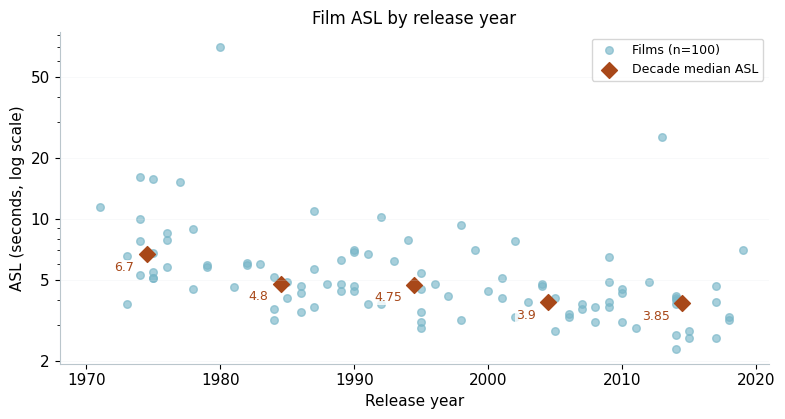

In [24]:
# Start Q1 with the decade medians, then point out the individual films.
display(q1_table.round(3))

# Same 100 films, log scale.
fig, ax = plt.subplots(figsize=(8, 4.8))
points = ax.scatter(main_films["release_year"], main_films["asl_seconds"],
                    s=30, alpha=0.65, color=palette["cyan"], label="Films (n=100)")
decade_midpoints = [d + 4.5 for d in range(1970, 2020, 10)]
ax.scatter(decade_midpoints, decade_summary["asl_median_seconds"], marker="D", s=65,
           color="#A84819", edgecolors="#A84819", label="Decade median ASL")
for year, median in zip(decade_midpoints, decade_summary.asl_median_seconds):
    ax.annotate(f"{median:g}", (year, median), xytext=(-9, -12), textcoords="offset points",
                ha="right", color="#A84819", fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 0.5})
ax.set_yscale("log")
ax.set_yticks([2, 5, 10, 20, 50])
ax.yaxis.set_major_formatter("{x:g}")
ax.set(title="Film ASL by release year", xlabel="Release year", ylabel="ASL (seconds, log scale)", xlim=(1968, 2021))
ax.set_xticks(range(1970, 2021, 10))
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.2)
assert len(points.get_offsets()) == 100
save_plot(fig, "fig01.png")

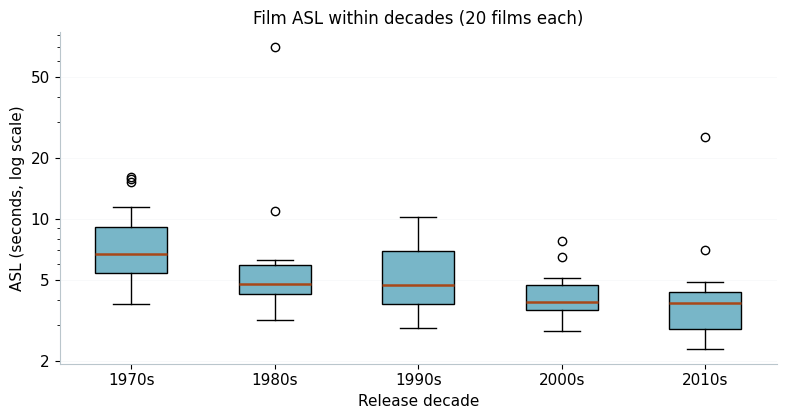

In [25]:
box_data = []
for decade in decade_order:
    box_data.append(main_films.loc[main_films["decade"].eq(decade), "asl_seconds"].to_numpy())
assert sum(len(values) for values in box_data) == 100
fig, ax = plt.subplots(figsize=(8, 4.8))
boxes = ax.boxplot(box_data, tick_labels=decade_order, patch_artist=True, medianprops={"color": "#A84819", "linewidth": 1.8})
for box in boxes["boxes"]:
    box.set_facecolor(palette["cyan"])
ax.set_yscale("log")
ax.set_yticks([2, 5, 10, 20, 50])
ax.yaxis.set_major_formatter("{x:g}")
ax.set(title="Film ASL within decades (20 films each)", xlabel="Release decade", ylabel="ASL (seconds, log scale)")
ax.grid(axis="y", alpha=0.2)
save_plot(fig, "fig02.png")

### M6 Q2 Compare genres
- **Comparison chart.** How do ASL medians change within genres with at least three films per decade? The panels show medians and group sizes.
- **Composition chart.** How are genre memberships distributed? A film can contribute several labels.

decade,1970s,1980s,1990s,2000s,2010s
genres,,,,,
Adventure,4,6,5,9,9
Drama,8,8,10,5,6
Thriller,5,7,5,3,7


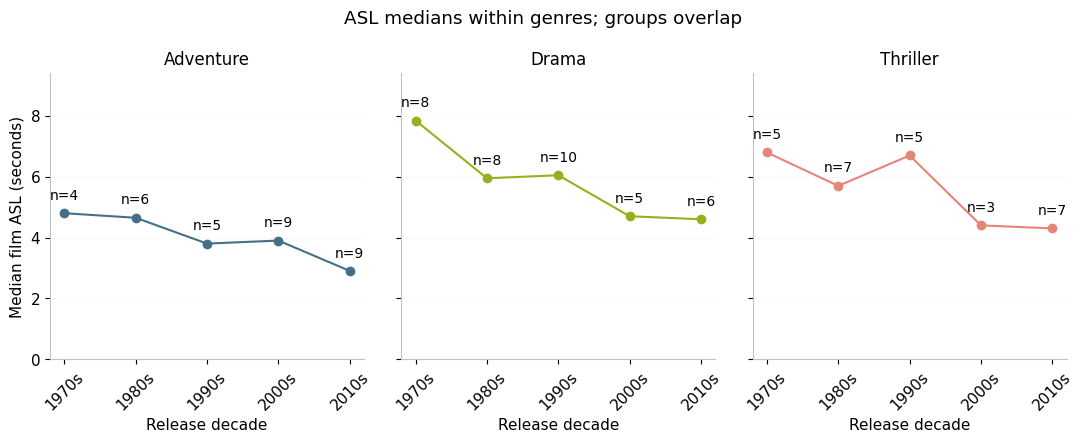

In [26]:
# Explain why the three genres qualify and what each n label counts.
genre_films = main_films.explode("genres").drop_duplicates(["tmdb_id", "genres"])
genre_coverage = genre_films.groupby(["genres", "decade"])["tmdb_id"].nunique().unstack("decade", fill_value=0)
genre_coverage = genre_coverage.reindex(columns=decade_order, fill_value=0).sort_index()
assert int(genre_coverage.to_numpy().sum()) == sum(len(set(names)) for names in main_films["genres"])

minimum_per_decade = 3
selected_genres = genre_coverage.index[genre_coverage.ge(minimum_per_decade).all(axis=1)].tolist()
display(genre_coverage.loc[selected_genres])
genre_decade_summary = (genre_films.loc[genre_films["genres"].isin(selected_genres)]
    .groupby(["genres", "decade"]).agg(
        film_count=("tmdb_id", "nunique"),
        film_asl_median_seconds=("asl_seconds", "median")))
genre_decade_summary = genre_decade_summary.reindex(
    pd.MultiIndex.from_product([selected_genres, decade_order], names=["genres", "decade"]))
assert genre_decade_summary["film_count"].ge(minimum_per_decade).all()

assert selected_genres == ["Adventure", "Drama", "Thriller"]

fig, axes = plt.subplots(1, 3, figsize=(11, 5), sharey=True)
upper = genre_decade_summary["film_asl_median_seconds"].max() * 1.20
for ax, genre in zip(axes, selected_genres):
    group = genre_decade_summary.loc[genre].reindex(decade_order)
    ax.plot(decade_order, group["film_asl_median_seconds"], marker="o", color=genre_colors[genre])
    for i, row in enumerate(group.to_dict("records")):
        ax.annotate(f"n={int(row['film_count'])}", (i, row["film_asl_median_seconds"]),
                    xytext=(0, 10), textcoords="offset points", ha="center", fontsize=10)
    ax.set(title=genre, xlabel="Release decade", ylim=(0, upper))
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(axis="y", alpha=0.2)
assert all(ax.get_ylim()[1] > genre_decade_summary["film_asl_median_seconds"].max() for ax in axes)
axes[0].set_ylabel("Median film ASL (seconds)")
fig.suptitle("ASL medians within genres; groups overlap")
save_plot(fig, "fig03.png")

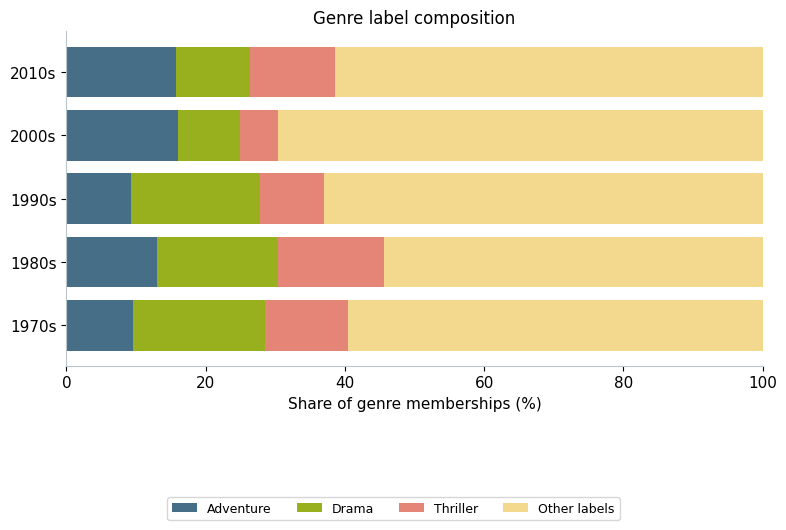

In [27]:
# One film can have several genres; these shares count label assignments.
composition = genre_coverage.loc[selected_genres].T.copy()
composition["Other labels"] = genre_coverage.sum(axis=0) - composition.sum(axis=1)
shares = composition.div(composition.sum(axis=1), axis=0) * 100
assert np.allclose(shares.sum(axis=1), 100)
fig, ax = plt.subplots(figsize=(8, 5.8))
left = np.zeros(len(decade_order))
for label, colour in zip(shares.columns, [genre_colors[name] for name in shares.columns]):
    ax.barh(decade_order, shares[label], left=left, label=label, color=colour)
    left += shares[label].to_numpy()
ax.set(title="Genre label composition", xlabel="Share of genre memberships (%)", xlim=(0, 100))
fig.legend(loc="lower center", bbox_to_anchor=(0.5, 0.08), fontsize=9, ncol=4)
save_plot(fig, "fig07.png", bottom=0.25)

### M6 Q3 Compare ASL and MSL
- **Comparison chart.** Do decade medians for ASL and MSL move together? Both series use the same frozen film/page pairs.
- The change table shows adjacent decades. See M2 for the film-level extremes.

,From decade,To decade,Change in median ASL (s),Change in median MSL (s),Direction agrees
0,1970s,1980s,-1.90,-0.90,True
1,1980s,1990s,-0.05,0.20,False
2,1990s,2000s,-0.85,-0.30,True
3,2000s,2010s,-0.05,-0.35,True


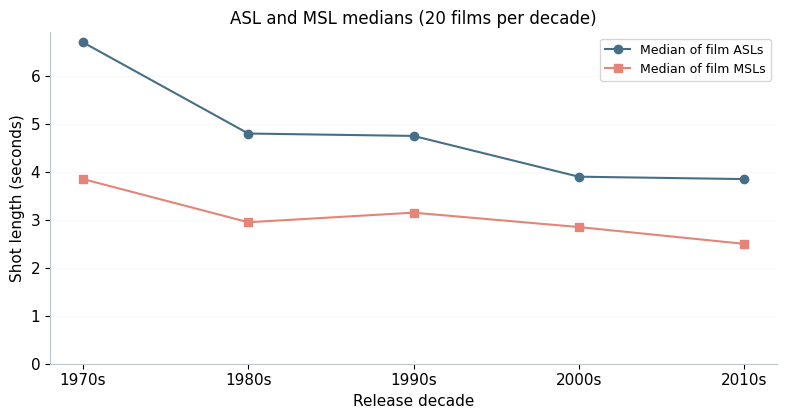

In [28]:
# Use the same paired films for ASL and MSL in Q3.
changes = rhythm_summary[["asl_median_seconds", "msl_median_seconds"]].diff().iloc[1:]
changes.insert(0, "From decade", decade_order[:-1])
changes.insert(1, "To decade", decade_order[1:])
changes["Direction agrees"] = np.sign(changes["asl_median_seconds"]) == np.sign(changes["msl_median_seconds"])
changes = changes.rename(columns={"asl_median_seconds": "Change in median ASL (s)", "msl_median_seconds": "Change in median MSL (s)"}).reset_index(drop=True)
assert changes["Direction agrees"].tolist() == [True, False, True, True]
display(changes.round(3))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(decade_order, rhythm_summary["asl_median_seconds"], marker="o", color=palette["blue"], label="Median of film ASLs")
ax.plot(decade_order, rhythm_summary["msl_median_seconds"], marker="s", color=palette["coral"], label="Median of film MSLs")
ax.set(title="ASL and MSL medians (20 films per decade)", xlabel="Release decade", ylabel="Shot length (seconds)", ylim=(0, None))
ax.legend()
ax.grid(axis="y", alpha=0.2)
save_plot(fig, "fig04.png")

### M6 Show genre connections
- **Network chart.** Which genres share films, and how many?
- Node area shows genre film count. Edge width and opacity show shared film count.

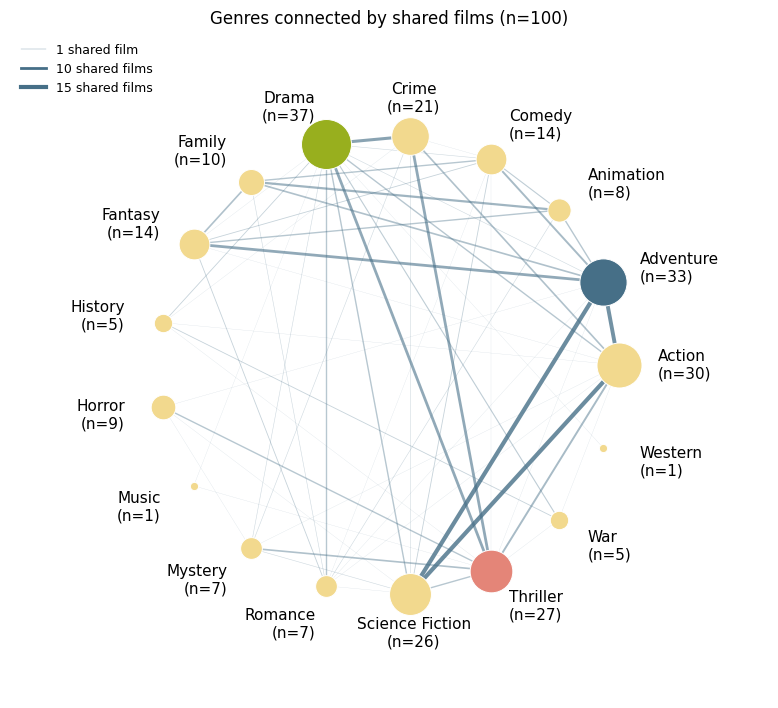

In [29]:
genre_counts = genre_films.groupby("genres")["tmdb_id"].nunique().sort_index()
edge_counts = {}
for labels in main_films["genres"]:
    for pair in itertools.combinations(sorted(set(labels)), 2):
        edge_counts[pair] = edge_counts.get(pair, 0) + 1
positions = {}
for i, genre in enumerate(genre_counts.index):
    angle = 2 * np.pi * i / len(genre_counts)
    positions[genre] = (np.cos(angle), np.sin(angle))
largest_edge = max(edge_counts.values())

def draw_genre_network():
    fig, ax = plt.subplots(figsize=(9, 8))
    for (left, right), count in sorted(edge_counts.items(), key=lambda item: item[1]):
        a, b = positions[left], positions[right]
        width = count * 0.20
        alpha = 0.18 + 0.62 * count / largest_edge
        colour = palette["blue"]
        ax.plot([a[0], b[0]], [a[1], b[1]], color=colour, linewidth=width, alpha=alpha)
    for genre, (x, y) in positions.items():
        count = int(genre_counts[genre])
        size = count * 35
        colour = genre_colors.get(genre, palette["sand"])
        ax.scatter(x, y, s=size, color=colour, edgecolors="white",
                   linewidths=0.7, zorder=3)
        label = f"{genre}\n(n={count})"
        alignment = "center"
        if abs(x) > 0.15:
            alignment = "left" if x > 0 else "right"
        offset = 1.17
        ax.text(x * offset, y * offset, label, ha=alignment, va="center", fontsize=11)
    for count in [1, 10, largest_edge]:
        label = f"{count} shared film" + ("s" if count != 1 else "")
        ax.plot([], [], color=palette["blue"], linewidth=count * 0.20, label=label)
    ax.legend(loc="upper left", fontsize=9, frameon=False)
    title = "Genres connected by shared films (n=100)"
    ax.set(title=title, xlim=(-1.65, 1.65), ylim=(-1.45, 1.45))
    ax.set_aspect("equal")
    ax.axis("off")
    return fig

save_plot(draw_genre_network(), "fig11.png")